# Nutritivne vrednosti brze hrane: linearna regresija

**Cilj:** predvideti količinu proteina u proizvodima brze hrane na osnovu drugih nutritivnih vrednosti i proveriti da li su ispunjene pretpostavke regresije.

**Postupak:** čišćenje podataka i zamena nedostajućih vrednosti medijanom, analiza korelacije, OLS regresija (statsmodels), dijagnostički grafici, provera multikolinearnosti pomoću VIF i poboljšanje modela.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import shapiro

In [6]:
data = pd.read_csv("data/fastfood.csv", na_values=["-", " ", ""])

display(data.head(10))
data.info()

,restaurant,item,calories,cal_fat,total_fat,sat_fat,trans_fat,cholesterol,sodium,total_carb,fiber,sugar,protein,calcium
0,Mcdonalds,Artisan Grilled Chicken Sandwich,380,60.0,7,2.0,0.0,95,1110,44,3.0,11,37.0,20.0
1,Mcdonalds,Single Bacon Smokehouse Burger,840,410.0,45,17.0,1.5,130,1580,62,2.0,18,46.0,20.0
2,Mcdonalds,Double Bacon Smokehouse Burger,1130,600.0,67,27.0,3.0,220,1920,63,3.0,18,70.0,50.0
3,Mcdonalds,Grilled Bacon Smokehouse Chicken Sandwich,750,280.0,31,10.0,0.5,155,1940,62,2.0,18,55.0,20.0
4,Mcdonalds,Crispy Bacon Smokehouse Chicken Sandwich,920,410.0,45,12.0,0.5,120,1980,81,4.0,18,46.0,20.0
5,Mcdonalds,Big Mac,540,250.0,28,10.0,1.0,80,950,46,3.0,9,25.0,15.0
6,Mcdonalds,Cheeseburger,300,100.0,12,5.0,0.5,40,680,33,2.0,7,15.0,10.0
7,Mcdonalds,Classic Chicken Sandwich,510,210.0,24,4.0,0.0,65,1040,49,3.0,6,25.0,2.0
8,Mcdonalds,Double Cheeseburger,430,190.0,21,11.0,1.0,85,1040,35,2.0,7,25.0,15.0
9,Mcdonalds,Double Quarter Pounder® with Cheese,770,400.0,45,21.0,2.5,175,1290,42,3.0,10,51.0,20.0


<class 'pandas.DataFrame'>
RangeIndex: 515 entries, 0 to 514
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   512 non-null    str    
 1   item         515 non-null    str    
 2   calories     515 non-null    int64  
 3   cal_fat      514 non-null    float64
 4   total_fat    515 non-null    int64  
 5   sat_fat      515 non-null    float64
 6   trans_fat    515 non-null    float64
 7   cholesterol  515 non-null    int64  
 8   sodium       515 non-null    int64  
 9   total_carb   515 non-null    int64  
 10  fiber        503 non-null    float64
 11  sugar        515 non-null    int64  
 12  protein      513 non-null    float64
 13  calcium      305 non-null    float64
dtypes: float64(6), int64(6), str(2)
memory usage: 56.5 KB


In [7]:
# Izbacujemo ekstremne vrednosti ukupnih masti
sub_data = data.loc[data['total_fat']<=125].copy()
sub_data.info()

<class 'pandas.DataFrame'>
Index: 513 entries, 0 to 514
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   restaurant   510 non-null    str    
 1   item         513 non-null    str    
 2   calories     513 non-null    int64  
 3   cal_fat      512 non-null    float64
 4   total_fat    513 non-null    int64  
 5   sat_fat      513 non-null    float64
 6   trans_fat    513 non-null    float64
 7   cholesterol  513 non-null    int64  
 8   sodium       513 non-null    int64  
 9   total_carb   513 non-null    int64  
 10  fiber        501 non-null    float64
 11  sugar        513 non-null    int64  
 12  protein      511 non-null    float64
 13  calcium      304 non-null    float64
dtypes: float64(6), int64(6), str(2)
memory usage: 60.1 KB


In [8]:
sub_data.isna().sum()


restaurant       3
item             0
calories         0
cal_fat          1
total_fat        0
sat_fat          0
trans_fat        0
cholesterol      0
sodium           0
total_carb       0
fiber           12
sugar            0
protein          2
calcium        209
dtype: int64

In [9]:
# Kolona calcium ima 209 nedostajućih vrednosti (oko 40%), pa je izbacujemo
sub_data.drop(columns='calcium', inplace=True)

In [10]:
# Zadržavamo samo numeričke kolone (restaurant i item su nazivi, a ne prediktori)
data_num = sub_data.select_dtypes(['number']).copy()
data_num.info()

<class 'pandas.DataFrame'>
Index: 513 entries, 0 to 514
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   calories     513 non-null    int64  
 1   cal_fat      512 non-null    float64
 2   total_fat    513 non-null    int64  
 3   sat_fat      513 non-null    float64
 4   trans_fat    513 non-null    float64
 5   cholesterol  513 non-null    int64  
 6   sodium       513 non-null    int64  
 7   total_carb   513 non-null    int64  
 8   fiber        501 non-null    float64
 9   sugar        513 non-null    int64  
 10  protein      511 non-null    float64
dtypes: float64(5), int64(6)
memory usage: 48.1 KB


In [11]:
# Kolone sa nedostajućim vrednostima
col_with_na = ['cal_fat', 'fiber', 'protein']

for col in col_with_na:
    series = data_num[col].dropna()
    stat, p = shapiro(series)
    print(f"{col}: p = {p:.5f} -> {'nije normalna' if p < 0.05 else 'normalna'} distribucija")

# Nijedna od tri kolone nema normalnu raspodelu, pa nedostajuće vrednosti menjamo medijanom

for col in col_with_na:
    median = data_num[col].median()
    data_num[col] = data_num[col].fillna(median)

# Provera da li smo sve zamenili
data_num.isna().any()

cal_fat: p = 0.00000 -> nije normalna distribucija
fiber: p = 0.00000 -> nije normalna distribucija
protein: p = 0.00000 -> nije normalna distribucija


calories       False
cal_fat        False
total_fat      False
sat_fat        False
trans_fat      False
cholesterol    False
sodium         False
total_carb     False
fiber          False
sugar          False
protein        False
dtype: bool

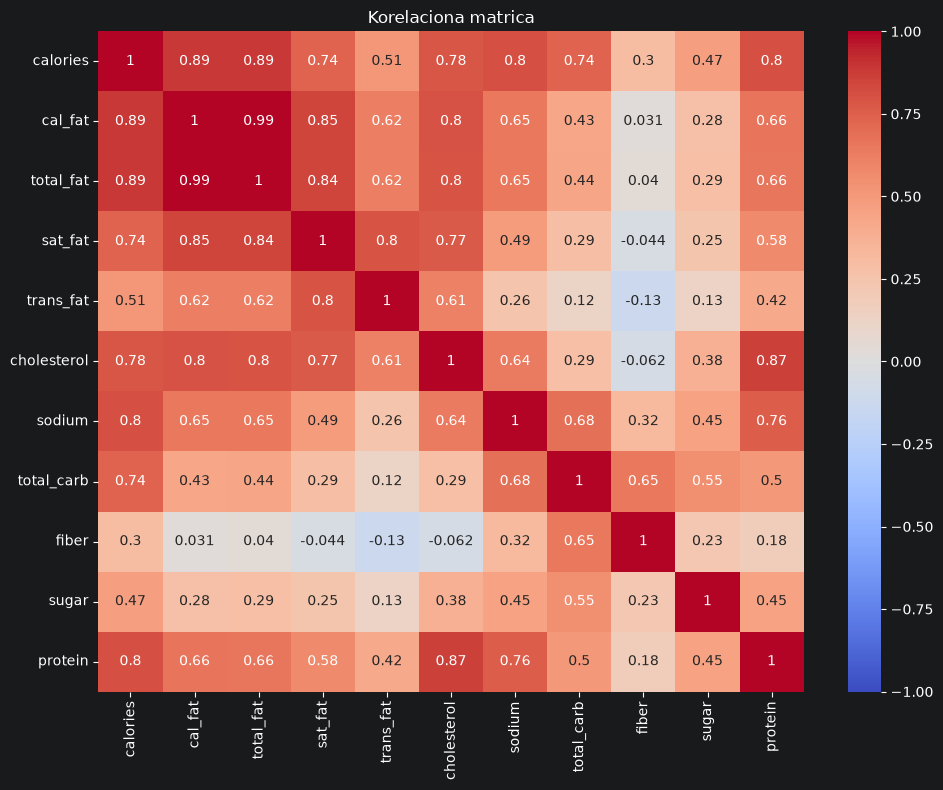

In [12]:
# Podaci su spremni za linearnu regresiju. Matrica korelacije nam pomaže da izaberemo atribute
import seaborn as sb

corr_matrix = data_num.corr(numeric_only=True).round(2)
plt.figure(figsize=(10, 8))
sb.heatmap(data_num.corr(numeric_only=True), annot=True,
           cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Korelaciona matrica")
plt.tight_layout()
plt.show()

In [13]:
# Za predviđanje atributa protein najveću korelaciju imaju:
#   cholesterol r = 0,87, calories r = 0,80, sodium r = 0,76
# Napomena: koeficijent korelacije pokazuje jačinu linearne veze, a NE koliko se protein
# menja kada se atribut poveća za jedinicu. Taj efekat daju koeficijenti regresije u nastavku.
target = 'protein'
features = ['cholesterol', 'calories', 'sodium']

In [14]:
# Podela na trening i test skup, stratifikovana po decilima proteina da oba skupa pokriju ceo opseg vrednosti

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(data_num, test_size=0.2, random_state=42, stratify=pd.qcut(data_num['protein'], q=10, duplicates='drop'))

print("Dužina train df:", len(train_df))
print("Dužina test df:", len(test_df))

Dužina train df: 410
Dužina test df: 103


In [15]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Pravljenje modela linearne regresije (metoda najmanjih kvadrata)

lm1 = smf.ols(f'{target} ~ ' + ' + '.join(features), data=train_df ).fit()
print(lm1.summary())

                            OLS Regression Results                            
Dep. Variable:                protein   R-squared:                       0.809
Model:                            OLS   Adj. R-squared:                  0.808
Method:                 Least Squares   F-statistic:                     574.9
Date:                Wed, 17 Jun 2026   Prob (F-statistic):          1.01e-145
Time:                        07:58:54   Log-Likelihood:                -1366.3
No. Observations:                 410   AIC:                             2741.
Df Residuals:                     406   BIC:                             2757.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       3.1398      0.773      4.063      

### Tumačenje modela
- **R² = 0,81**: tri atributa objašnjavaju oko 81% varijanse proteina.
- Sva tri koeficijenta su statistički značajna (p < 0,05).
- **cholesterol = 0,179**: jedan mg holesterola više znači u proseku oko 0,18 g proteina više, kada su ostali atributi nepromenjeni.
- **sodium = 0,0067** i **calories = 0,0062**: manji efekat po jedinici, ali su ti atributi na mnogo većoj skali.
- Veliki "condition number" ukazuje na moguću **multikolinearnost** (calories je povezan sa ostalim prediktorima), što proveravamo pomoću VIF u nastavku.

In [16]:
# Predikcije na test skupu

y_true = test_df['protein']
X_test = test_df[['cholesterol', 'sodium' , 'calories']]

y_pred = lm1.predict(X_test)

# Poređenje stvarnih i predviđenih vrednosti

results = pd.DataFrame({
    'Stvarno': y_true.values,
    'Predvidjeno': y_pred.round(2)
})
# Prikaz prvih 10

print(results.head(10))

     Stvarno  Predvidjeno
118     21.0        19.17
427     24.0        27.32
275     11.0        17.28
448     14.0        14.73
454     16.0        15.99
32      48.0        44.22
378     36.0        25.69
386     17.0        15.48
301     15.0        15.65
462     17.0        16.61


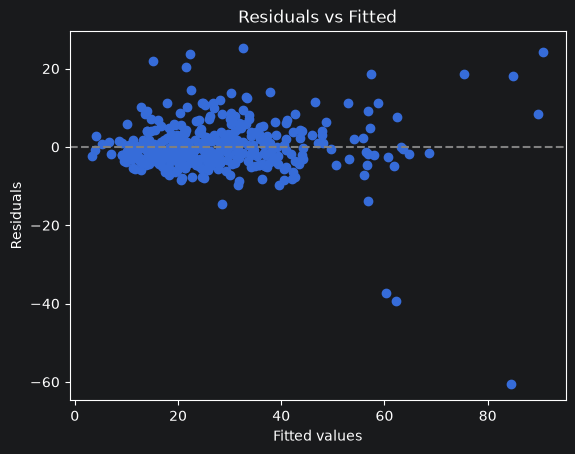

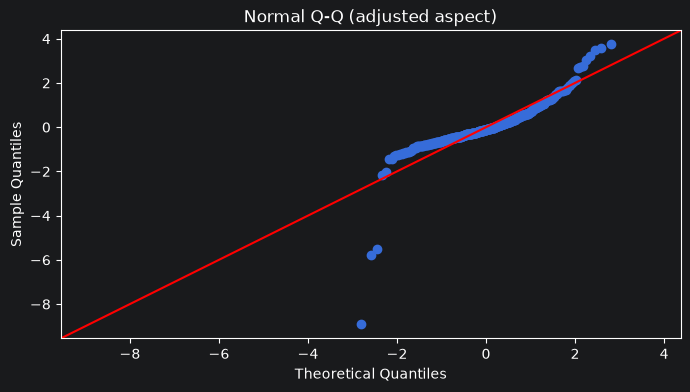

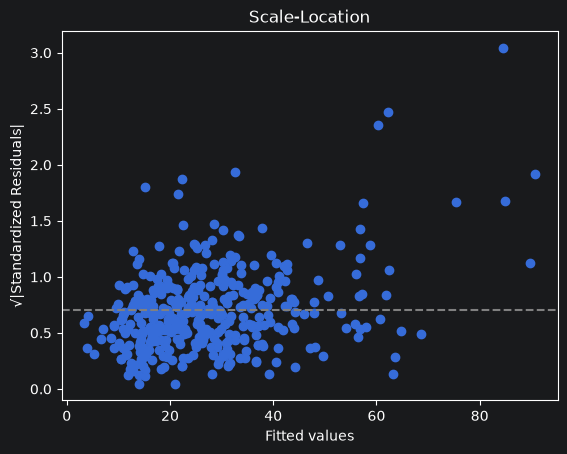

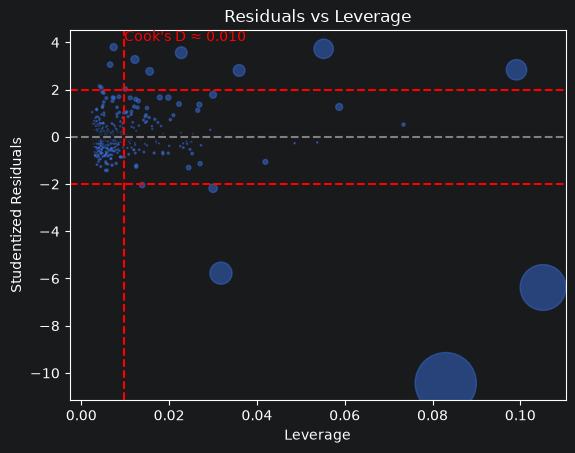

In [17]:
# Dijagnostika regresije: linearnost, normalnost reziduala, homoskedastičnost i uticajne tačke
#Grafikoni
# Residuals vs Fitted
plt.scatter(lm1.fittedvalues, lm1.resid)
plt.axhline(0, color='gray', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Fitted")
plt.show()
# Normal Q-Q
sm.qqplot(lm1.resid, line='45', fit=True)
plt.gcf().set_size_inches(8, 4)
plt.title("Normal Q-Q (adjusted aspect)")
plt.show()
# Scale-Location
influence = lm1.get_influence()
std_resid = influence.resid_studentized_internal
abs_sqrt_resid = np.sqrt(np.abs(std_resid))
plt.scatter(lm1.fittedvalues, abs_sqrt_resid)
plt.axhline(np.mean(abs_sqrt_resid), color='gray', linestyle='--')
plt.xlabel("Fitted values")
plt.ylabel("√|Standardized Residuals|")
plt.title("Scale-Location")
plt.show()
# Residuals vs Leverage + Cook's D threshold
leverage = influence.hat_matrix_diag
stud_resid = influence.resid_studentized_external
cooks_d = influence.cooks_distance[0]
n = len(lm1.model.endog)
thresh = 4 / n

plt.scatter(leverage, stud_resid, s=1000 * cooks_d, alpha=0.5)
plt.axhline(0, color='gray', linestyle='--')
plt.axhline(2, color='red', linestyle='--')
plt.axhline(-2, color='red', linestyle='--')
plt.axvline(thresh, color='red', linestyle='--')
plt.text(thresh, plt.ylim()[1]*0.9, f"Cook's D ≈ {thresh:.3f}", color='red')
plt.xlabel("Leverage")
plt.ylabel("Studentized Residuals")
plt.title("Residuals vs Leverage")
plt.show()

In [20]:
# Provera multikolinearnosti (pravilo: koren VIF veći od 2 ukazuje na problem)
import statsmodels.api as sm
X = sm.add_constant(train_df[features])
vif = pd.Series([variance_inflation_factor(X.values,i) for i in range(X.shape[1])], index=X.columns)
print('koren VIF prve verzije: \n', np.sqrt(vif))
# Pošto je koren VIF za calories veći od 2, postoji multikolinearnost, koja može dovesti do nepouzdanih procena.
# Novi model pravimo samo sa atributima sodium i cholesterol
lm2 = smf.ols(f'{target} ~ cholesterol + sodium', data=train_df ).fit()

# Provera VIF za lm2

X = sm.add_constant(train_df[['cholesterol', 'sodium']])
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns)
print('√VIF druge verzije:\n', np.sqrt(vif))
# Nema više multikolinearnosti

koren VIF prve verzije: 
 const          2.297968
cholesterol    1.601010
calories       2.072595
sodium         1.675465
dtype: float64
√VIF druge verzije:
 const          2.172578
cholesterol    1.293928
sodium         1.293928
dtype: float64


## Zaključak
- Holesterol, natrijum i kalorije objašnjavaju oko 81% varijacije proteina.
- Dijagnostika pokazuje nekoliko ekstremnih reziduala i uticajnih tačaka (Cook-ova distanca), što je očekivano za nutritivne podatke sa ekstremnim proizvodima iz menija.
- Atribut calories je izbačen zbog multikolinearnosti, pa konačni model koristi holesterol i natrijum.